# Forward heat equation — finite differences and validation

**Research project:** Numerical Solution and PDE-Constrained Optimization of the Two-Dimensional Heat Equation

We solve $u_t=\alpha(u_{xx}+u_{yy})+f(x,y)$ on $(0,1)^2$ with zero initial temperature and zero Dirichlet boundary values.

For $f(x,y)=\sin(\pi x)\sin(\pi y)$, the exact solution is

$$u(x,y,t)=\frac{1-e^{-2\alpha\pi^2t}}{2\alpha\pi^2}\sin(\pi x)\sin(\pi y).$$

The explicit finite difference update is

$$u_{i,j}^{n+1}=(1-2r_x-2r_y)u_{i,j}^n+r_x(u_{i+1,j}^n+u_{i-1,j}^n)+r_y(u_{i,j+1}^n+u_{i,j-1}^n)+\Delta t f_{i,j},$$

where $r_x=\alpha\Delta t/h_x^2$, $r_y=\alpha\Delta t/h_y^2$. Stability requires $r_x+r_y\leq 1/2$.

We test convergence against the analytical solution; this notebook does **not** yet solve the inverse optimization problem.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
def exact_solution(X, Y, t, alpha):
    amplitude = -np.expm1(-2 * alpha * np.pi**2 * t) / (2 * alpha * np.pi**2)
    return amplitude * np.sin(np.pi * X) * np.sin(np.pi * Y)


def solve_heat(nx=24, ny=None, T=0.1, alpha=0.1, safety=0.8):
    """Explicit FTCS on the unit square with zero initial/Dirichlet conditions."""
    ny = nx if ny is None else ny
    hx, hy = 1 / nx, 1 / ny
    dt_max = 1 / (2 * alpha * (1 / hx**2 + 1 / hy**2))
    nt = int(np.ceil(T / (safety * dt_max)))
    dt = T / nt
    rx, ry = alpha * dt / hx**2, alpha * dt / hy**2
    assert rx + ry <= 0.5 + 1e-12, "Unstable time step"

    x = np.linspace(0, 1, nx + 1)
    y = np.linspace(0, 1, ny + 1)
    X, Y = np.meshgrid(x, y, indexing="ij")
    source = np.sin(np.pi * X) * np.sin(np.pi * Y)
    u = np.zeros_like(source)

    for _ in range(nt):
        u_next = u.copy()
        u_next[1:-1, 1:-1] = (
            (1 - 2 * rx - 2 * ry) * u[1:-1, 1:-1]
            + rx * (u[2:, 1:-1] + u[:-2, 1:-1])
            + ry * (u[1:-1, 2:] + u[1:-1, :-2])
            + dt * source[1:-1, 1:-1]
        )
        u = u_next

    truth = exact_solution(X, Y, T, alpha)
    relative_l2 = np.linalg.norm(u - truth) / np.linalg.norm(truth)
    return {"X": X, "Y": Y, "numerical": u, "exact": truth,
            "relative_l2": relative_l2, "dt": dt, "steps": nt,
            "rx": rx, "ry": ry}


Steps: 116, dt: 0.0008621
Stability r_x+r_y: 0.3972 <= 0.5
Relative L2 error: 0.00080427


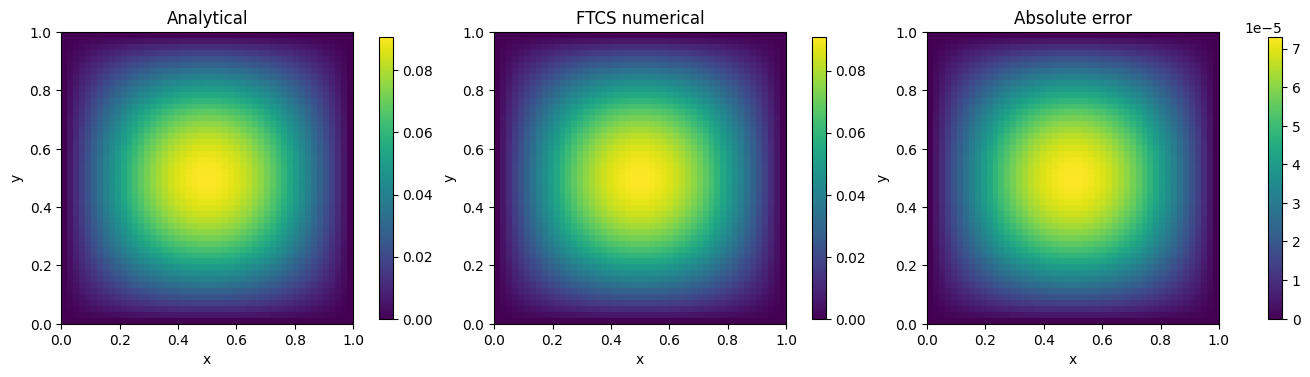

In [14]:
result = solve_heat(nx=48)
print(f"Steps: {result['steps']}, dt: {result['dt']:.7f}")
print(f"Stability r_x+r_y: {result['rx'] + result['ry']:.4f} <= 0.5")
print(f"Relative L2 error: {result['relative_l2']:.8f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
for ax, data, title in zip(axes, [result['exact'], result['numerical'],
                                 np.abs(result['exact'] - result['numerical'])],
                           ['Analytical', 'FTCS numerical', 'Absolute error']):
    im = ax.imshow(data.T, origin='lower', extent=[0, 1, 0, 1], cmap='viridis')
    ax.set(xlabel='x', ylabel='y', title=title)
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.show();

**Mesh Refinement and Numerical Convergence Analysis**

This experiment investigates the convergence behaviour of the explicit FTCS scheme by progressively refining the spatial grid. The timestep is adjusted to satisfy the stability condition. Numerical errors are calculated relative to the analytical solution, and observed convergence orders are estimated from successive grid refinements.

In [16]:
# @title Mesh Refinement and Numerical Convergence Analysis

grid_sizes = [12, 24, 48]
errors = []
for n in grid_sizes:
    r = solve_heat(nx=n)
    errors.append(r['relative_l2'])
    print(f"Grid {n:2d} x {n:2d}: steps={r['steps']:4d}, relative L2 error={r['relative_l2']:.8e}")
for k in range(1, len(grid_sizes)):
    rate = np.log(errors[k-1] / errors[k]) / np.log(grid_sizes[k] / grid_sizes[k-1])
    print(f"Observed order {grid_sizes[k-1]} -> {grid_sizes[k]}: {rate:.3f}")
assert all(b < a for a,b in zip(errors, errors[1:])), 'Errors did not decrease'


Grid 12 x 12: steps=   8, relative L2 error=1.18237360e-02
Grid 24 x 24: steps=  29, relative L2 error=3.22412924e-03
Grid 48 x 48: steps= 116, relative L2 error=8.04273339e-04
Observed order 12 -> 24: 1.875
Observed order 24 -> 48: 2.003


## Interpretation

As the spatial grid is refined, the timestep is reduced proportionally to $h^2$ to preserve stability. Since FTCS is first order in time and second order in space, this joint refinement is expected to produce approximately second-order convergence for the smooth test solution.

**Next milestone:** incorporate arbitrary source basis functions and construct the linear observation-response matrix for inverse reconstruction.